<a href="https://colab.research.google.com/github/HoJin26/Linear-Algebra/blob/main/ex02_transform_tiefighter_%E1%84%87%E1%85%A2%E1%84%91%E1%85%A9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [1048]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [1049]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [1050]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [1051]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

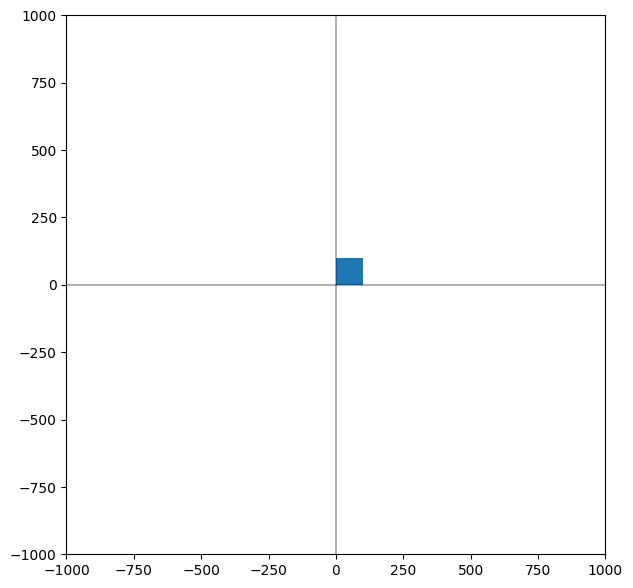

In [1052]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

### 이동

In [1053]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx],
                [0.0, 1.0, dy],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

### 회전

In [1054]:
def rotate(p, theta):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 회전 변환 행렬 생성
  m = np.array([
      [np.cos(theta), -np.sin(theta), 0.0],
      [np.sin(theta), np.cos(theta), 0.0],
      [0.0, 0.0, 1.0]
  ])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

### 크기

In [1055]:
def scale(p, sx, sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 크기 변환 행렬 생성
  m = np.array([[sx, 0.0, 0.0],
                [0.0, sy, 0.0],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

### 기울기

In [1056]:
def shear_x(p, sx):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. x축 방향 전단 변환 행렬 생성
  m = np.array([
      [1.0, sx, 0.0],
      [0.0, 1.0, 0.0],
      [0.0, 0.0, 1.0]
  ])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [1057]:
def shear_y(p, sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y축 방향 전단 변환 행렬 생성
  m = np.array([
      [1.0, 0.0, 0.0],
      [sy, 1.0, 0.0],
      [0.0, 0.0, 1.0]
  ])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

### 반전

In [1058]:
def reflect_x(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. x축 대칭 변환 행렬 생성 (y값을 -y로)
  m = np.array([
      [1.0, 0.0, 0.0],
      [0.0, -1.0, 0.0],
      [0.0, 0.0, 1.0]
  ])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [1059]:
def reflect_y(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y축 대칭 변환 행렬 생성 (x값을 -x로)
  m = np.array([
      [-1.0, 0.0, 0.0],
      [0.0, 1.0, 0.0],
      [0.0, 0.0, 1.0]
  ])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [1060]:
def reflect_origin(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 원점 대칭 변환 행렬 생성 (x -> -x, y -> -y)
  m = np.array([
      [-1.0, 0.0, 0.0],
      [0.0, -1.0, 0.0],
      [0.0, 0.0, 1.0]
  ])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [1061]:
def reflect_yx(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y=x 대칭 변환 행렬 생성 (x -> y, y -> x)
  m = np.array([
      [0.0, 1.0, 0.0],
      [1.0, 0.0, 0.0],
      [0.0, 0.0, 1.0]
  ])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

###중앙 조종석


In [1062]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)

  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

###왼쪽 날개축


In [1063]:
def draw_left_arm(ax, p1, p2, p3, p4):  # 왼쪽 날개축
  # --- 1. 위쪽 축  ---
  # 원점 이동
  u1 = translate(p1, -LEN/2, -LEN/2)
  u2 = translate(p2, -LEN/2, -LEN/2)
  u3 = translate(p3, -LEN/2, -LEN/2)
  u4 = translate(p4, -LEN/2, -LEN/2)

  # 크기 변환
  u1 = scale(u1, 7.0, 0.8)
  u2 = scale(u2, 7.0, 0.8)
  u3 = scale(u3, 7.0, 0.8)
  u4 = scale(u4, 7.0, 0.8)

  # 기울기 변환
  u1 = shear_y(u1, -0.25)
  u2 = shear_y(u2, -0.25)
  u3 = shear_y(u3, -0.25)
  u4 = shear_y(u4, -0.25)

  # 오른쪽 위로 이동
  u1 = translate(u1, 300, 100)
  u2 = translate(u2, 300, 100)
  u3 = translate(u3, 300, 100)
  u4 = translate(u4, 300, 100)

  draw_rectangle(ax, u1, u2, u3, u4)

  # --- 2. 아래쪽 축  ---
  # 원점 이동
  d1 = translate(p1, -LEN/2, -LEN/2)
  d2 = translate(p2, -LEN/2, -LEN/2)
  d3 = translate(p3, -LEN/2, -LEN/2)
  d4 = translate(p4, -LEN/2, -LEN/2)

  # 크기 변환
  d1 = scale(d1, 7.0, 0.8)
  d2 = scale(d2, 7.0, 0.8)
  d3 = scale(d3, 7.0, 0.8)
  d4 = scale(d4, 7.0, 0.8)

  # 기울기 변환
  d1 = shear_y(d1, 0.25)
  d2 = shear_y(d2, 0.25)
  d3 = shear_y(d3, 0.25)
  d4 = shear_y(d4, 0.25)

  # 오른쪽 아래로 이동
  d1 = translate(d1, 300, -100)
  d2 = translate(d2, 300, -100)
  d3 = translate(d3, 300, -100)
  d4 = translate(d4, 300, -100)

  draw_rectangle(ax, d1, d2, d3, d4)

### 왼쪽 날개


In [1064]:
def draw_left_wing(ax, p1, p2, p3, p4):  # 왼쪽 날개
  # --- 1. 위쪽 날개 반쪽 ---
  # 원점 이동
  u1 = translate(p1, -LEN/2, -LEN/2)
  u2 = translate(p2, -LEN/2, -LEN/2)
  u3 = translate(p3, -LEN/2, -LEN/2)
  u4 = translate(p4, -LEN/2, -LEN/2)

  # 크기 변환
  u1 = scale(u1, 1.2, 5)
  u2 = scale(u2, 1.2, 5)
  u3 = scale(u3, 1.2, 5)
  u4 = scale(u4, 1.2, 5)

  # 기울기 변환
  u1 = shear_y(u1, 0.9)
  u2 = shear_y(u2, 0.9)
  u3 = shear_y(u3, 0.9)
  u4 = shear_y(u4, 0.9)

  # 오른쪽 위로 이동
  u1 = translate(u1, 650, 195)
  u2 = translate(u2, 650, 195)
  u3 = translate(u3, 650, 195)
  u4 = translate(u4, 650, 195)

  draw_rectangle(ax, u1, u2, u3, u4)

  # --- 2. 아래쪽 날개 반쪽 ---
  # 원점 이동
  d1 = translate(p1, -LEN/2, -LEN/2)
  d2 = translate(p2, -LEN/2, -LEN/2)
  d3 = translate(p3, -LEN/2, -LEN/2)
  d4 = translate(p4, -LEN/2, -LEN/2)

  # 크기 변환
  d1 = scale(d1, 1.2, 5)
  d2 = scale(d2, 1.2, 5)
  d3 = scale(d3, 1.2, 5)
  d4 = scale(d4, 1.2, 5)

  # 기울기 변환
  d1 = shear_y(d1, -0.9)
  d2 = shear_y(d2, -0.9)
  d3 = shear_y(d3, -0.9)
  d4 = shear_y(d4, -0.9)

  # 오른쪽 아래로 이동
  d1 = translate(d1, 650, -195)
  d2 = translate(d2, 650, -195)
  d3 = translate(d3, 650, -195)
  d4 = translate(d4, 650, -195)

  draw_rectangle(ax, d1, d2, d3, d4)

###오른쪽 날개축


In [1065]:
def draw_right_arm(ax, p1, p2, p3, p4):  # 왼쪽 날개축
  # --- 1. 위쪽 축 ---
  # 원점 이동
  u1 = translate(p1, -LEN/2, -LEN/2)
  u2 = translate(p2, -LEN/2, -LEN/2)
  u3 = translate(p3, -LEN/2, -LEN/2)
  u4 = translate(p4, -LEN/2, -LEN/2)

  # 크기 변환
  u1 = scale(u1, 7.0, 0.8)
  u2 = scale(u2, 7.0, 0.8)
  u3 = scale(u3, 7.0, 0.8)
  u4 = scale(u4, 7.0, 0.8)

  # 기울기 변환
  u1 = shear_y(u1, 0.25)
  u2 = shear_y(u2, 0.25)
  u3 = shear_y(u3, 0.25)
  u4 = shear_y(u4, 0.25)

  # 왼쪽 위로 이동
  u1 = translate(u1, -300, 100)
  u2 = translate(u2, -300, 100)
  u3 = translate(u3, -300, 100)
  u4 = translate(u4, -300, 100)

  draw_rectangle(ax, u1, u2, u3, u4)

  # --- 2. 아래쪽 축 ---
  # 원점 이동
  d1 = translate(p1, -LEN/2, -LEN/2)
  d2 = translate(p2, -LEN/2, -LEN/2)
  d3 = translate(p3, -LEN/2, -LEN/2)
  d4 = translate(p4, -LEN/2, -LEN/2)

  # 크기 변환
  d1 = scale(d1, 7.0, 0.8)
  d2 = scale(d2, 7.0, 0.8)
  d3 = scale(d3, 7.0, 0.8)
  d4 = scale(d4, 7.0, 0.8)

  # 기울기 변환
  d1 = shear_y(d1, -0.25)
  d2 = shear_y(d2, -0.25)
  d3 = shear_y(d3, -0.25)
  d4 = shear_y(d4, -0.25)

  # 왼쪽 아래로 이동
  d1 = translate(d1, -300, -100)
  d2 = translate(d2, -300, -100)
  d3 = translate(d3, -300, -100)
  d4 = translate(d4, -300, -100)

  draw_rectangle(ax, d1, d2, d3, d4)

### 오른쪽 날개


In [1066]:
def draw_right_wing(ax, p1, p2, p3, p4):  # 오른쪽 날개
  # --- 1. 위쪽 날개 반쪽 ---
  # 원점 이동
  u1 = translate(p1, -LEN/2, -LEN/2)
  u2 = translate(p2, -LEN/2, -LEN/2)
  u3 = translate(p3, -LEN/2, -LEN/2)
  u4 = translate(p4, -LEN/2, -LEN/2)
  # 크기 변환
  u1 = scale(u1, 1.2, 5)
  u2 = scale(u2, 1.2, 5)
  u3 = scale(u3, 1.2, 5)
  u4 = scale(u4, 1.2, 5)

  # 기울기 변환
  u1 = shear_y(u1, -0.9)
  u2 = shear_y(u2, -0.9)
  u3 = shear_y(u3, -0.9)
  u4 = shear_y(u4, -0.9)
  # 왼쪽 위로 이동
  u1 = translate(u1, -650, 195)
  u2 = translate(u2, -650, 195)
  u3 = translate(u3, -650, 195)
  u4 = translate(u4, -650, 195)

  draw_rectangle(ax, u1, u2, u3, u4)

  # --- 2. 아래쪽 날개 반쪽 ---
  # 원점 이동
  d1 = translate(p1, -LEN/2, -LEN/2)
  d2 = translate(p2, -LEN/2, -LEN/2)
  d3 = translate(p3, -LEN/2, -LEN/2)
  d4 = translate(p4, -LEN/2, -LEN/2)

  # 크기 변환
  d1 = scale(d1, 1.2, 5)
  d2 = scale(d2, 1.2, 5)
  d3 = scale(d3, 1.2, 5)
  d4 = scale(d4, 1.2, 5)

  # 기울기 변환
  d1 = shear_y(d1, 0.9)
  d2 = shear_y(d2, 0.9)
  d3 = shear_y(d3, 0.9)
  d4 = shear_y(d4, 0.9)

  # 왼쪽 아래로 이동
  d1 = translate(d1, -650, -195)
  d2 = translate(d2, -650, -195)
  d3 = translate(d3, -650, -195)
  d4 = translate(d4, -650, -195)

  draw_rectangle(ax, d1, d2, d3, d4)

### tiefighter 그리기

In [1067]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)
  draw_left_arm(ax, p1, p2, p3, p4) # 왼쪽 날개축
  draw_left_wing(ax, p1, p2, p3, p4) # 왼쪽 날개
  draw_right_arm(ax, p1, p2, p3, p4) # 오른쪽 날개축
  draw_right_wing(ax, p1, p2, p3, p4) # 오른쪽 날개


### 3. main

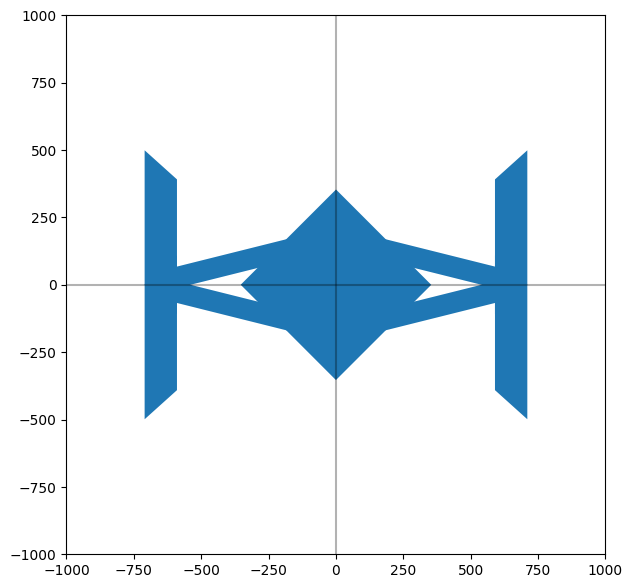

In [1068]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()